# Part A. The announcement

## Step 1. Measure each gilt’s daily yield change

Convert yields to basis points and subtract the preceding business close for the same ISIN. Leave the change missing after a gap. Assign each gilt its remaining maturity and eligibility on that date. The file contains 4,987 observations for 44 gilts across 118 trading days. Before the announcement, the median absolute daily move was 2.034 bp.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from html import escape
from IPython.display import HTML, display

def show_table(frame, caption):
    table = frame.to_html(border=0, na_rep="—")
    title = f'<caption style="caption-side:top;text-align:left">{escape(caption)}</caption>'
    display(HTML(table.replace("<thead>", title + "<thead>", 1)))


out = Path("part_a_outputs")
out.mkdir(exist_ok=True)
event = pd.Timestamp("2016-08-04")
base = pd.Timestamp("2016-08-03")
sectors = ["Ineligible", "3–7", "7–15", "15+"]

def maturity_sector(years):
    labels = np.select(
        [years < 3, years < 7, years <= 15],
        sectors[:3], default=sectors[3]
    )
    return pd.Categorical(labels, categories=sectors, ordered=True)

daily = pd.read_csv("gilt_prices_daily.csv", dtype={"isin": "string"})
required = {"gilt_name", "isin", "redemption_date", "date", "clean_price",
            "yield_percent", "modified_duration"}
assert required.issubset(daily.columns)
daily["isin"] = daily["isin"].str.strip().replace("", pd.NA)
for col in ["date", "redemption_date"]:
    daily[col] = pd.to_datetime(daily[col], format="mixed", dayfirst=True)
for col in ["yield_percent", "modified_duration"]:
    daily[col] = pd.to_numeric(daily[col])

assert daily[["isin", "date", "redemption_date"]].notna().all().all()
assert not np.isinf(daily[["yield_percent", "modified_duration"]]).any().any()
assert daily.groupby("isin")["redemption_date"].nunique().le(1).all()
key_counts = daily.groupby(["isin", "date"]).size()
assert key_counts.eq(1).all()

calendar = pd.DatetimeIndex(daily["date"].unique()).sort_values()
assert (calendar.min(), calendar.max()) == (pd.Timestamp("2016-07-15"), pd.Timestamp("2016-12-30"))
assert (calendar.dayofweek < 5).all()
day_number = pd.Series(range(1, len(calendar) + 1), index=calendar)
daily = daily.sort_values(["isin", "date"]).reset_index(drop=True)
daily["t"] = daily["date"].map(day_number)
daily["yield_bp"] = 100 * daily["yield_percent"]

by_gilt = daily.groupby("isin", sort=False)
consecutive = by_gilt["t"].diff().eq(1)
daily["change_bp"] = by_gilt["yield_bp"].diff().where(consecutive)
daily["duration_prev"] = by_gilt["modified_duration"].shift().where(consecutive)
daily["maturity_years"] = (daily["redemption_date"] - daily["date"]).dt.days / 365.25
daily["sector"] = maturity_sector(daily["maturity_years"])

assert day_number.loc["2016-07-15"] == 1 and day_number.loc["2016-08-08"] == 17
for earlier, later, distance in [("2016-08-26", "2016-08-30", 1), ("2016-08-08", "2016-08-15", 5)]:
    assert earlier in day_number and later in day_number and day_number[later] - day_number[earlier] == distance
assert daily.loc[daily["t"].eq(1), "change_bp"].isna().all()
assert list(maturity_sector(pd.Series([2.99, 3, 7, 15, 15.01]))) == [
    "Ineligible", "3–7", "7–15", "7–15", "15+"
]
daily.to_csv(out / "daily_changes.csv", index=False)
ordinary = daily.loc[daily["date"].between("2016-07-18", base), "change_bp"]
print(f"Median absolute daily gilt move before the announcement: {ordinary.abs().median():.2f} bp")

Median absolute daily gilt move before the announcement: 2.03 bp


## Step 2. Measure the announcement move across maturities

All 42 gilt yields fell on 4 August. From the ineligible group through the three eligible sectors, mean changes were $-5.87$, $-15.20$, $-16.51$ and $-15.04$ bp. Against each group’s own daily mean changes over the preceding 13 trading days, these were $-2.64$, $-4.99$, $-3.87$ and $-3.61$ standard deviations. The 7–15-year sector fell furthest in bp. The 3–7-year sector had the most unusual fall for its own history.

The two plots use remaining maturity on 4 August and modified duration at the 3 August close. Falls generally grew with duration at the short end, peaked around the middle of the curve and eased among the longest gilts. At the three-year cutoff, the 2.96- and 3.09-year gilts had nearly identical prior durations (2.90 and 2.92 years) and fell 9.69 and 11.55 bp. The eligible gilt fell 1.86 bp further. Only three gilts lay within six months of the cutoff, two below and one above. A smooth change through the boundary is plausible, and the sparse observations also allow a discrete jump.

Under H2a, removing duration risk reduces the compensation investors require across maturities. The fall on both sides fits that prediction, although the largest falls were not at the longest durations. Under H2b, eligible gilts become scarce because some investors prefer particular maturities. Their larger average fall fits local scarcity, but the cutoff evidence alone is too thin to distinguish the two channels.

Conventional gilt yield changes on 4 August 2016 (bp). Benchmark: sector daily means, 18 July–3 August. Move in SD is unitless.


,announcement_bp,normal_sd_bp,normal_days,event_gilts,move_in_sd
sector,,,,,
Ineligible,-5.867,2.226,13,8,-2.635
3–7,-15.196,3.044,13,10,-4.993
7–15,-16.505,4.269,13,8,-3.866
15+,-15.041,4.171,13,16,-3.606


Within six months of 3 years: 2 gilts below, 1 at or above.


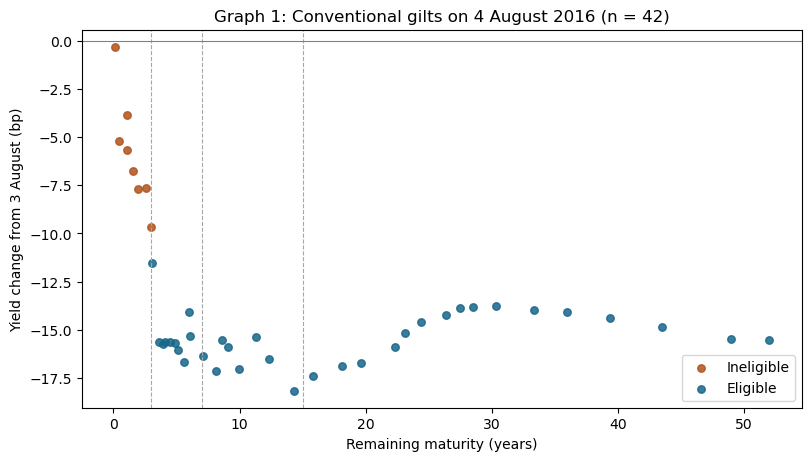

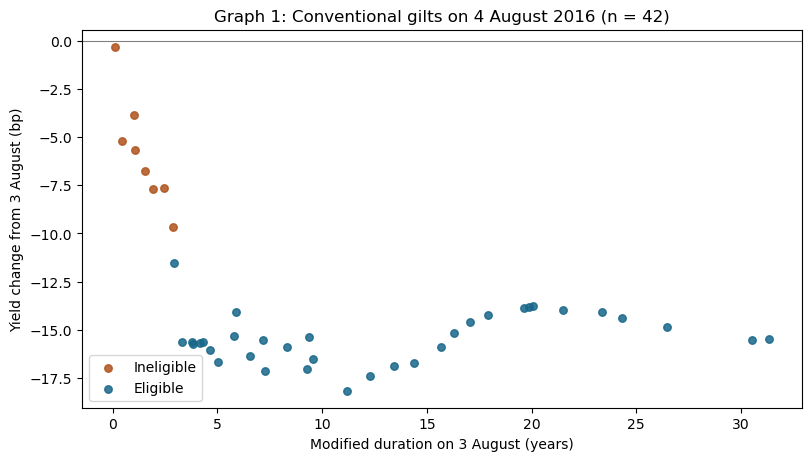

In [24]:
announcement = daily.loc[daily["date"].eq(event)].copy()
announcement.to_csv(out / "announcement_gilts.csv", index=False)

sector_means = (
    daily.groupby(["date", "sector"], observed=True)["change_bp"]
    .mean().unstack("sector").reindex(index=calendar, columns=sectors)
)
prior = sector_means.loc["2016-07-18":base]
assert len(prior) == 13

summary = pd.DataFrame({
    "announcement_bp": sector_means.loc[event],
    "normal_sd_bp": prior.std(ddof=1),
    "normal_days": prior.count(),
    "event_gilts": announcement.groupby("sector", observed=True)["change_bp"].count()
}).reindex(sectors)
summary["event_gilts"] = summary["event_gilts"].fillna(0).astype(int)
summary["move_in_sd"] = summary["announcement_bp"].div(
    summary["normal_sd_bp"].where(summary["normal_sd_bp"] > 0)
)
summary.to_csv(out / "announcement_by_sector.csv")
print(
    "Conventional gilt yield changes on 4 August 2016 (bp). "
    "Benchmark: sector daily means, 18 July–3 August. Move in SD is unitless."
)
show_table(summary.round(3),
           '4 August 2016 announcement. Mean daily gilt yield changes and pre-announcement SDs (bp). Counts are gilts and benchmark days.')
near = announcement.dropna(subset=["change_bp"]).query("2.5 <= maturity_years <= 3.5")
below = near["maturity_years"].lt(3).sum()
print(f"Within six months of 3 years: {below} gilts below, {len(near) - below} at or above.")

for x, xlabel in [("maturity_years", "Remaining maturity (years)"),
                  ("duration_prev", "Modified duration on 3 August (years)")]:
    points = announcement.dropna(subset=[x, "change_bp"])
    fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
    eligible = points["sector"].ne("Ineligible")
    for label, mask, colour in [("Ineligible", ~eligible, "#ae521c"),
                                ("Eligible", eligible, "#17668a")]:
        ax.scatter(points.loc[mask, x], points.loc[mask, "change_bp"],
                   label=label, color=colour, s=29, alpha=0.85)
    if x == "maturity_years":
        for boundary in [3, 7, 15]:
            ax.axvline(boundary, color="0.65", ls="--", lw=0.8)
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set(xlabel=xlabel, ylabel="Yield change from 3 August (bp)",
           title=f"Graph 1: Conventional gilts on 4 August 2016 (n = {len(points)})")
    ax.legend()
    fig.savefig(out / f"announcement_{x}.png", dpi=300)
    plt.show()

## Step 3. Test whether eligible gilts fell unusually far

Subtract the average daily change of ineligible gilts from the average across all eligible gilts. On 4 August the gap was $-9.564$ bp ($z=-3.421$), more negative than on any of the other 116 days. Across 4–5 August it reached $-10.686$ bp ($z=-2.541$), with one of 115 other two-day windows at least as negative. The extra day widened the gap by 1.12 bp. Its standardised magnitude fell because the benchmark SD rose from 2.90 bp for a single day to 4.47 bp for two days. The 9.56 bp gap compares all maturities on either side of three years. The nearest pair in Step 2 differed by only 1.86 bp.

Alongside £60bn in additional gilt purchases, the Bank cut Bank Rate by 25 bp to 0.25%, introduced the Term Funding Scheme to support pass-through to bank lending and announced up to £10bn of corporate bond purchases. Subtracting the ineligible group removes a common parallel shift. A revision to expected short rates can affect two- and twenty-year yields differently, and corporate bond purchases can redirect demand towards particular maturities. The observed gap therefore captures the differential reaction to the whole package. [Bank of England decision, 4 August 2016](https://www.bankofengland.co.uk/monetary-policy-summary-and-minutes/2016/mpc-august-2016)

In [3]:
eligible = daily["sector"].ne("Ineligible").rename("eligible")
group_means = (
    daily.groupby(["date", eligible])["change_bp"].mean()
    .unstack("eligible").reindex(index=calendar, columns=[False, True])
)
gaps = group_means.set_axis(["ineligible_bp", "eligible_bp"], axis=1)
gaps["gap_bp"] = gaps["eligible_bp"] - gaps["ineligible_bp"]
gaps["two_day_bp"] = gaps["gap_bp"] + gaps["gap_bp"].shift(-1)

def compare_window(values):
    actual = values.loc[event]
    other = values.drop(index=event).dropna()
    mean, sd = other.mean(), other.std(ddof=1)
    can_rank = pd.notna(actual) and not other.empty
    return pd.Series({
        "event_bp": actual,
        "other_mean_bp": mean,
        "other_sd_bp": sd,
        "z": (actual - mean) / sd if can_rank and sd > 0 else np.nan,
        "at_least_as_negative": int(other.le(actual).sum()) if can_rank else np.nan,
        "other_windows": len(other)
    })

assert day_number.loc["2016-08-05"] == day_number.loc[event] + 1
announcement_tests = pd.DataFrame({
    "4 August": compare_window(gaps["gap_bp"]),
    "4–5 August": compare_window(gaps["two_day_bp"])
}).T
counts = ["at_least_as_negative", "other_windows"]
announcement_tests[counts] = announcement_tests[counts].astype("Int64")
gaps.to_csv(out / "daily_eligibility_gaps.csv", index_label="date")
announcement_tests.to_csv(out / "announcement_tests.csv", index_label="window")
print(
    "Eligible minus ineligible gilt yield changes (bp), 15 July–30 December 2016. "
    "Each event is compared with the other valid windows of the same length; z is unitless."
)
show_table(announcement_tests.round(3),
           '4 August announcement. Eligible minus ineligible yield changes (bp) against other valid 2016 windows. The z-score is in standard deviations.')


Eligible minus ineligible gilt yield changes (bp), 15 July–30 December 2016. Each event is compared with the other valid windows of the same length; z is unitless.


,event_bp,other_mean_bp,other_sd_bp,z,at_least_as_negative,other_windows
4 August,-9.564,0.361,2.902,-3.421,0,116
4–5 August,-10.686,0.675,4.472,-2.541,1,115


### Step 3 sensitivity · A strictly pre-announcement benchmark

The required test uses every other valid window. Here the reference window must close by 3 August, so the two-day comparators start no later than 2 August. The one-day gap of $-9.564$ bp was more negative than all 13 earlier days ($z=-4.151$). The two-day gap of $-10.686$ bp was more negative than all 12 earlier windows ($z=-2.739$). These ranks describe a small pre-programme sample.

In [4]:
window_ends = pd.Series(calendar, index=calendar)
strict_pre = {}
for days, label, column in [(1, "4 August", "gap_bp"), (2, "4–5 August", "two_day_bp")]:
    ends_before_event = window_ends.shift(1 - days).lt(event)
    reference_and_event = gaps[column].loc[ends_before_event | (gaps.index == event)]
    strict_pre[label] = compare_window(reference_and_event)

pre_announcement_tests = pd.concat(
    {"Full sample": announcement_tests, "Pre-announcement only": pd.DataFrame(strict_pre).T},
    names=["benchmark", "window"]
)
pre_announcement_tests[counts] = pre_announcement_tests[counts].astype("Int64")
pre_announcement_tests.to_csv(out / "pre_announcement_benchmark.csv")
show_table(pre_announcement_tests.round(4),
           '4 August announcement. Eligible minus ineligible yield changes (bp) against full-sample and strictly earlier windows; counts are comparison windows.')


## Step 4. Track how long the announcement move lasted

Measure each gilt’s yield relative to its 3 August close and hold its announcement-day sector fixed. During the preceding ten business days, sector yields moved in both directions. There was no sustained common decline into 4 August comparable with the announcement-day fall. Investors could already have anticipated part of the programme before this window.

At the 5 August close, the 3–7, 7–15 and over-15-year sectors were still 14.07, 14.78 and 15.41 bp below their 3 August closes. This is the clearest evidence of persistence because the Bank’s first purchase came on 8 August. At day ten the three sectors were still below the reference close, but their paths then include actual purchases and subsequent news.

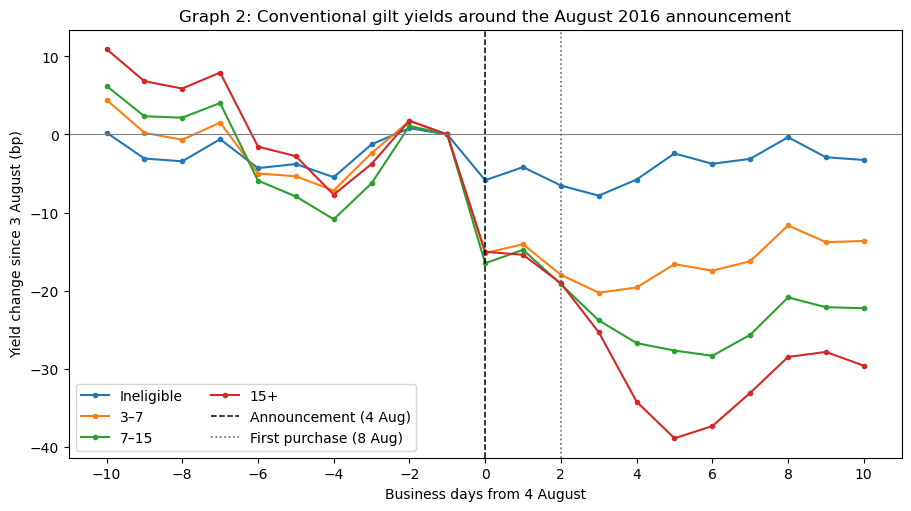

In [27]:
event_t = day_number.loc[event]
window = daily.loc[daily["t"].between(event_t - 10, event_t + 10)].copy()
window["tau"] = window["t"] - event_t
window["event_sector"] = maturity_sector(
    (window["redemption_date"] - event).dt.days / 365.25
)

base_yield = daily.loc[daily["date"].eq(base)].set_index("isin")["yield_bp"]
assert base_yield.index.is_unique
window["from_base_bp"] = window["yield_bp"] - window["isin"].map(base_yield)

path = window.groupby(["tau", "event_sector"], observed=False)["from_base_bp"].agg(
    mean_bp="mean", n_gilts="count"
)
curves = path["mean_bp"].unstack().reindex(columns=sectors)

assert day_number.loc["2016-08-08"] - event_t == 2
assert set(curves.index) == set(range(-10, 11))
assert np.allclose(curves.loc[-1].dropna(), 0)
np.testing.assert_allclose(curves.loc[0], summary["announcement_bp"], equal_nan=True)
path.to_csv(out / "announcement_path.csv")

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
curves.plot(ax=ax, marker="o", markersize=3)
ax.axhline(0, color="0.5", lw=0.8)
ax.axvline(0, color="black", ls="--", lw=1.1, label="Announcement (4 Aug)")
ax.axvline(2, color="0.4", ls=":", lw=1.2, label="First purchase (8 Aug)")
ax.set(xlabel="Business days from 4 August", ylabel="Yield change since 3 August (bp)",
       title=("Graph 2: Conventional gilt yields around the August 2016 announcement"),
       xticks=range(-10, 11, 2))
ax.legend(ncol=2)
fig.savefig(out / "announcement_path.png", dpi=300)
plt.show()

# Part B. The purchase operations

## Step 5. Identify which gilts could have been bought

Pair each operation with gilts priced at the preceding business close, keep those with at least three years left on the operation date, and mark actual purchases by date and ISIN. This gives 1,851 eligible gilt–operation pairs, with 33–35 eligible gilts per operation. All 361 purchase records appear once.

In [6]:
b_out = Path("part_b_outputs")
b_out.mkdir(exist_ok=True)
keys = ["operation_date", "isin"]
proceeds_col = "total_allocation_proceeds_mn"
purchases = pd.read_csv("purchase_operations.csv", dtype={"isin": "string", proceeds_col: "string"})
required = {*keys, "bond", "total_allocation_nominal_mn", "total_allocation_proceeds_mn",
            "amount_outstanding_mn", "mod_duration_prev"}
assert required.issubset(purchases.columns)
purchases["isin"] = purchases["isin"].str.strip().replace("", pd.NA)
purchases["operation_date"] = pd.to_datetime(purchases["operation_date"], format="mixed", dayfirst=True)
assert purchases[keys].notna().all().all() and not purchases.duplicated(keys).any()

proceeds_text = purchases.set_index(keys)[proceeds_col].astype(object).rename("proceeds_text")

for col in ["total_allocation_nominal_mn", "amount_outstanding_mn",
            "total_allocation_proceeds_mn", "mod_duration_prev"]:
    purchases[col] = pd.to_numeric(purchases[col]).astype(float)
    assert not np.isinf(purchases[col]).any()
assert purchases["total_allocation_nominal_mn"].gt(0).all()

ops = purchases[["operation_date"]].drop_duplicates().sort_values("operation_date").copy()
ops["t0"] = ops["operation_date"].map(day_number)
assert len(ops) == 54 and ops["t0"].notna().all()
date_by_t = pd.Series(calendar, index=day_number.values)
ops["prev_business_date"] = (ops["t0"] - 1).map(date_by_t)
assert ops.iloc[0]["operation_date"] == pd.Timestamp("2016-08-08")
assert ops.iloc[0]["t0"] == 17 and ops.iloc[0]["prev_business_date"] == pd.Timestamp("2016-08-05")

assert ops.iloc[-1]["operation_date"] == pd.Timestamp("2016-12-14")
if "prev_business_date" in purchases:
    reported = pd.to_datetime(purchases["prev_business_date"], format="mixed", dayfirst=True)
    expected = purchases["operation_date"].map(ops.set_index("operation_date")["prev_business_date"])
    assert reported.eq(expected).all()

daily["clean_price"] = pd.to_numeric(daily["clean_price"])
assert not np.isinf(daily["clean_price"]).any()
quotes = daily.set_index(["isin", "date"])[["yield_bp", "clean_price"]]
gilts = daily[["isin", "redemption_date"]].drop_duplicates()
assert gilts["isin"].is_unique and quotes.index.is_unique
universe = ops.merge(gilts, how="cross")
assert len(universe) == len(ops) * len(gilts)
prior_keys = pd.MultiIndex.from_arrays([universe["isin"], universe["prev_business_date"]])
universe = universe.loc[quotes["clean_price"].reindex(prior_keys).notna().to_numpy()].copy()
universe["maturity_years"] = (universe["redemption_date"] - universe["operation_date"]).dt.days / 365.25
universe["sector"] = maturity_sector(universe["maturity_years"])
universe = universe.loc[universe["sector"].ne("Ineligible")].copy()
bought = pd.MultiIndex.from_frame(purchases[keys])
universe["purchased"] = pd.MultiIndex.from_frame(universe[keys]).isin(bought).astype(int)
omitted = bought.difference(pd.MultiIndex.from_frame(universe[keys]))
assert omitted.empty
assert not universe.duplicated(keys).any() and universe["purchased"].sum() == len(purchases)
universe.to_csv(b_out / "operation_universe.csv", index=False)
show_table(universe.groupby("operation_date")["purchased"].agg(eligible_gilts="size", purchased_gilts="sum"),
           'Eligible and purchased gilts per operation, August–December 2016. Counts are distinct ISINs.')


,eligible_gilts,purchased_gilts
operation_date,,
2016-08-08,34,4
2016-08-09,34,14
2016-08-10,34,6
2016-08-15,34,6
2016-08-16,34,10
2016-08-17,34,6
2016-08-22,34,5
2016-08-23,34,14
2016-08-24,34,6


**Previous-close check.** For each purchase, compare its supplied prior yield, clean price and modified duration with the daily quote for the same ISIN on the preceding business date. All three fields matched on all 361 purchases.

In [7]:
previous = purchases["operation_date"].map(ops.set_index("operation_date")["prev_business_date"])
prior_index = pd.MultiIndex.from_arrays([purchases["isin"], previous])
quote_fields = daily.set_index(["isin", "date"])[["modified_duration", "yield_percent", "clean_price"]]
previous_quotes = quote_fields.reindex(prior_index).set_axis(purchases.index)
rows = []
for field, column, unit, scale in [
    ("mod_duration_prev", "modified_duration", "years", 1),
    ("yield_percent_prev", "yield_percent", "bp", 100),
    ("clean_price_prev", "clean_price", "£ per £100 nominal", 1)
]:
    if field in purchases:
        supplied = pd.to_numeric(purchases[field])
        quoted = previous_quotes[column]
        difference = (supplied - quoted).abs() * scale
        rows.append({"field": field, "unit": unit, "comparable": difference.count(),
                     "missing_in_purchase_file": supplied.isna().sum(),
                     "missing_in_daily_file": quoted.isna().sum(),
                     "max_absolute_difference": difference.max()})
prior_quote_check = pd.DataFrame(rows).set_index("field")
prior_quote_check.to_csv(b_out / "prior_quote_check.csv")
show_table(prior_quote_check,
           'Prior-close quote reconciliation for the 2016 gilt purchases. Counts are purchase records; units are given by field.')


,unit,comparable,missing_in_purchase_file,missing_in_daily_file,max_absolute_difference
field,,,,,
mod_duration_prev,years,361,0,0,0.0
yield_percent_prev,bp,361,0,0,0.0
clean_price_prev,£ per £100 nominal,361,0,0,0.0


## Step 6. Match each purchase to unpurchased gilts

Of 361 purchases, 179 had an unpurchased gilt on each side in the same sector and operation. Weighting the two neighbours reproduces the target maturity and helps account for a sloping yield curve. Another 166 had a neighbour on only one side, which receives full weight. These comparisons retain a maturity difference that can matter when the curve steepens or flattens.

The short sector had 55 bracketed and 52 one-sided matches. The middle sector had 22 and 52, so most middle-sector purchases relied on one neighbour. The long sector had 102 bracketed, 62 one-sided and all 16 unmatched purchases. On 30 August the Bank bought every eligible long-sector gilt, leaving no same-sector comparison. The matched sample therefore covers 345 purchases in 53 of the 54 operations.

In [8]:
def match_gilt(row, candidates):
    years = row.maturity_years
    shorter = candidates.loc[candidates["maturity_years"] < years]
    longer = candidates.loc[candidates["maturity_years"] > years]
    lo = shorter.loc[shorter["maturity_years"].idxmax()] if len(shorter) else None
    hi = longer.loc[longer["maturity_years"].idxmin()] if len(longer) else None
    if lo is not None and hi is not None:
        w_lo = (hi.maturity_years - years) / (hi.maturity_years - lo.maturity_years)
        kind, w_hi = "bracketed", 1 - w_lo
    elif lo is not None or hi is not None:
        kind, w_lo, w_hi = "nearest-neighbour", float(lo is not None), float(hi is not None)
    else:
        kind, w_lo, w_hi = "unmatched", np.nan, np.nan
    return (row.operation_date, row.isin, row.sector, years, kind,
            lo["isin"] if lo is not None else pd.NA, hi["isin"] if hi is not None else pd.NA,
            lo.maturity_years if lo is not None else np.nan,
            hi.maturity_years if hi is not None else np.nan, w_lo, w_hi)

records = []
for _, group in universe.groupby(["operation_date", "sector"], observed=True):
    candidates = group.loc[group["purchased"].eq(0)].sort_values("isin")
    for row in group.loc[group["purchased"].eq(1)].itertuples():
        records.append(match_gilt(row, candidates))

matches = pd.DataFrame(records, columns=[
    *keys, "sector", "maturity_years", "match_type", "isin_L", "isin_U",
    "maturity_L", "maturity_U", "w_L", "w_U"
])
assert len(matches) == len(purchases) and not matches.duplicated(keys).any()
weights = matches.loc[matches["match_type"].ne("unmatched"), ["w_L", "w_U"]]
assert weights.ge(0).all().all() and weights.le(1).all().all()
np.testing.assert_allclose(weights.sum(axis=1), 1)
br = matches.loc[matches["match_type"].eq("bracketed")]
np.testing.assert_allclose(br["w_L"] * br["maturity_L"] + br["w_U"] * br["maturity_U"],
                           br["maturity_years"])
match_counts = pd.crosstab(matches["sector"], matches["match_type"]).reindex(
    index=sectors[1:], columns=["bracketed", "nearest-neighbour", "unmatched"], fill_value=0
)
matches.to_csv(b_out / "comparison_gilts.csv", index=False)
match_counts.to_csv(b_out / "match_counts_by_sector.csv")
show_table(match_counts,
           '2016 gilt purchases by maturity sector and comparison type. Counts are gilt–operation pairs.')


match_type,bracketed,nearest-neighbour,unmatched
sector,,,
3–7,55,52,0
7–15,22,52,0
15+,102,62,16


## Step 7. Measure the purchased gilt’s move relative to its neighbours

Follow each purchase from five business days before to ten after its operation, with comparison gilts and weights fixed. At each horizon subtract the neighbours’ change since day $-1$ from the purchased gilt’s change. This gives abnormal yield in bp and abnormal clean price in £ per £100 nominal. All 345 matched purchases have both measures at all 16 horizons, including zero at the baseline.

In [9]:
horizons = pd.DataFrame({"h": range(-5, 11)})
event_dates = ops[["operation_date", "t0"]].merge(horizons, how="cross")
event_dates["date"] = (event_dates["t0"] + event_dates["h"]).map(date_by_t)
assert event_dates["date"].notna().all()
panel = matches.merge(event_dates, on="operation_date").sort_values([*keys, "h"])
assert not panel.duplicated([*keys, "h"]).any() and len(panel) == 16 * len(matches)

for code, suffix in [("isin", ""), ("isin_L", "_L"), ("isin_U", "_U")]:
    quote_keys = pd.MultiIndex.from_arrays([panel[code], panel["date"]])
    panel[["yield_bp" + suffix, "clean_price" + suffix]] = quotes.reindex(quote_keys).to_numpy()

for measure, abnormal in [("yield_bp", "AY"), ("clean_price", "AP")]:
    lower = (panel["w_L"] * panel[measure + "_L"]).mask(panel["w_L"].eq(0), 0)
    upper = (panel["w_U"] * panel[measure + "_U"]).mask(panel["w_U"].eq(0), 0)
    panel[measure + "_C"] = lower + upper
    spread = panel[measure] - panel[measure + "_C"]
    baseline = spread.loc[panel["h"].eq(-1)].copy()
    baseline.index = pd.MultiIndex.from_frame(panel.loc[panel["h"].eq(-1), keys])
    panel[abnormal] = spread - baseline.reindex(pd.MultiIndex.from_frame(panel[keys])).to_numpy()
    assert panel.loc[panel["h"].eq(-1), abnormal].dropna().eq(0).all()
assert panel.loc[panel["match_type"].eq("unmatched"), ["AY", "AP"]].isna().all().all()


## Step 8. Flag windows affected by a later purchase

Flag a window once a later operation buys its target or either comparison gilt. Among all 361 purchases, contamination was zero on days one and two and reached 5.82% on day four. It jumped to 74.52% on day five, when the Bank usually returned to the sector, and reached 87.26% on day ten. A later purchase can move either side of the measured yield gap.

This matters for the Step 9 figure. On day five the full matched sample gives $+0.308$ bp. The clean sample gives $+0.038$ bp from just 84 purchases in 26 operations. By day ten only 43 matched purchases in 17 operations remain clean. From day five onwards the full path mixes operations, while the clean path increasingly represents gilts that escaped another purchase. Changes in sample composition also affect the difference between the paths.

In [10]:
first_overlap = pd.Series(pd.NaT, index=matches.index, dtype="datetime64[ns]")
for operation_date, group in matches.groupby("operation_date"):
    later = purchases.loc[purchases["operation_date"].gt(operation_date)]
    next_buy = later.groupby("isin")["operation_date"].min()
    dates = pd.concat([group[col].map(next_buy) for col in ["isin", "isin_L", "isin_U"]], axis=1)
    first_overlap.loc[group.index] = dates.min(axis=1)

overlaps = matches[keys].assign(first_overlap=first_overlap).set_index(keys)["first_overlap"]
first_date = overlaps.reindex(pd.MultiIndex.from_frame(panel[keys])).to_numpy()
panel["contaminated"] = (panel["h"].gt(0) & panel["date"].ge(first_date)).astype(int)
assert panel.loc[panel["h"].le(0), "contaminated"].eq(0).all()
assert panel.groupby(keys)["contaminated"].diff().dropna().ge(0).all()
contamination = panel.loc[panel["h"].gt(0)].groupby("h")["contaminated"].agg(
    rows="size", contaminated_rows="sum", share="mean"
)
panel.to_csv(b_out / "event_time_panel.csv", index=False)
contamination.to_csv(b_out / "contamination_by_horizon.csv")
show_table(contamination,
           'Overlap after a 2016 gilt purchase. Each horizon counts gilt–operation pairs; share is the contaminated fraction.')


,rows,contaminated_rows,share
h,,,
1,361,0,0.000000
2,361,0,0.000000
3,361,1,0.002770
4,361,21,0.058172
5,361,269,0.745152
6,361,271,0.750693
7,361,271,0.750693
8,361,271,0.750693
9,361,275,0.761773


## Step 9. Test for temporary operation-day pressure

The average abnormal yield rose from $-0.154$ bp at $h=-5$ to $-0.059$ at $h=-2$ and zero at the reference close $h=-1$. Each pre-operation point’s interval before the reference close includes zero. The raw operation-day move of $+0.0711$ bp (95% CI $[0.0048,0.1375]$) continued that upward drift. H1 predicts a downward departure on purchase day.



**Reversal.** Among 324 uncontaminated purchases in 52 operations the estimate is $+0.0876$ bp (SE $0.1244$, 95% CI $[-0.1622,0.3373]$). Its sign fits a rebound, but the operation-day test did not establish an initial fall. The interval allows a 0.20 bp rebound or a further relative decline. A 0.50 bp average rebound lies outside it.

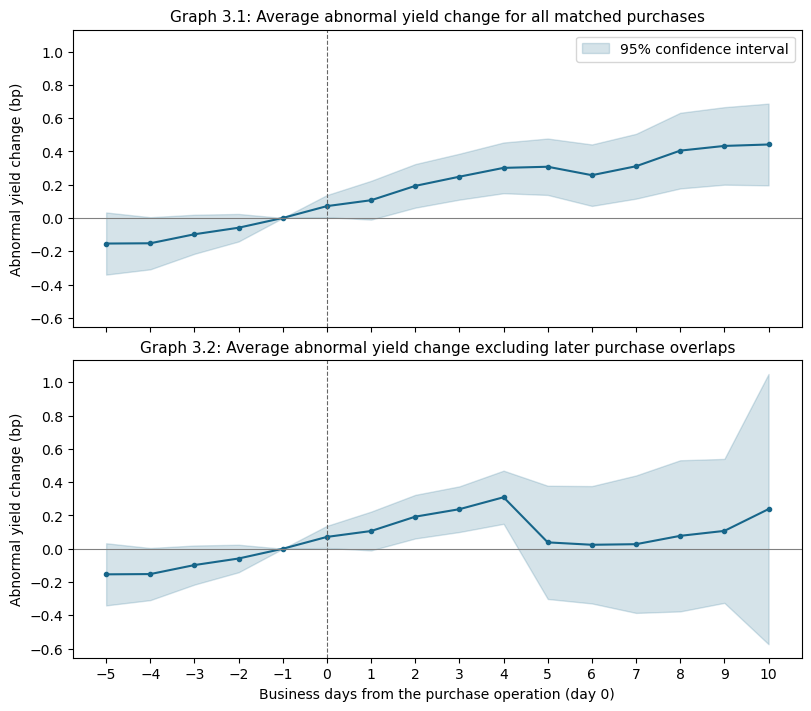

In [44]:
titles = {
    "All": "Graph 3.1: Average abnormal yield change for all matched purchases",
    "Uncontaminated": "Graph 3.2: Average abnormal yield change excluding later purchase overlaps",
}

fig, axes = plt.subplots(
    2, 1, figsize=(8, 7), sharex=True, sharey=True, constrained_layout=True
)

for ax, (sample, title) in zip(axes, titles.items()):
    curve = event_study.loc[event_study["sample"].eq(sample)].set_index("h").sort_index()

    ax.fill_between(
        curve.index, curve["lower_95_bp"].to_numpy(), curve["upper_95_bp"].to_numpy(),
        color="#17668a", alpha=0.18, label="95% confidence interval"
    )
    ax.plot(curve.index, curve["mean_bp"], color="#17668a", marker="o", ms=3)
    ax.axhline(0, color="0.5", lw=0.8)
    ax.axvline(0, color="0.4", ls="--", lw=0.8)
    ax.set_title(title, fontsize=11)
    ax.set_ylabel("Abnormal yield change (bp)")

axes[0].legend()
axes[1].set(xlabel="Business days from the purchase operation (day 0)", xticks=horizons)
fig.savefig(b_out / "operation_event_study.png", dpi=300)
plt.show()

### Step 9 sensitivity · Earlier purchases in the baseline window

An earlier purchase can affect the drift measured from the $h=-5$ close to $h=-1$. Recompute both Step 9 tests after excluding prior purchases of the target or either comparison gilt. Excluding days $-4$ to $-1$ leaves 338 purchases and an operation-day estimate of $+0.0433$ bp. Including the $-5$ starting close leaves 84 purchases and $+0.0162$ bp (95% interval $[-0.1076,0.1400]$). The strict rule leaves 29 operations contributing to the estimate, compared with 53 in the original test. The reversal still requires a clean forward window through day four.

In [12]:
pre = panel.loc[panel["h"].between(-5, -1), [*keys, "h", "date", "isin_L", "isin_U"]].copy()
purchase_keys = pd.MultiIndex.from_frame(purchases[keys])
pre["prior_hit"] = False
for leg in ["isin", "isin_L", "isin_U"]:
    lookup = pd.MultiIndex.from_arrays([pre["date"], pre[leg]])
    pre["prior_hit"] |= lookup.isin(purchase_keys)

latest_hit = pre.loc[pre["prior_hit"]].groupby(keys)["h"].max().reindex(effects.index, fill_value=-6)
backward_rows, counts_by_operation = [], []
for test, column in [("Operation day", "operation_day_bp"), ("Four-day reversal", "day_4_reversal_bp")]:
    observed = effects[column].notna()
    for rule, start in [("Original", 0), ("Clear h=-4 to -1", -4), ("Clear h=-5 to -1", -5)]:
        keep = observed & latest_hit.lt(start)
        estimate = operation_summary(effects.loc[keep, column])
        op_counts = pd.DataFrame({"original": observed, "retained": keep}).groupby(level="operation_date").sum()
        op_counts["excluded"] = op_counts["original"] - op_counts["retained"]
        counts_by_operation.append(op_counts.assign(test=test, pre_window=rule).reset_index())
        backward_rows.append({"test": test, "pre_window": rule, **estimate,
                              "excluded_purchases": op_counts["excluded"].sum(),
                              "operations_with_exclusions": op_counts["excluded"].gt(0).sum()})

pre_counts = pd.concat(counts_by_operation, ignore_index=True)
pre_sensitivity = pd.DataFrame(backward_rows)
pre_sensitivity["t_stat"] = pre_sensitivity["mean_bp"].div(pre_sensitivity["se_bp"].where(pre_sensitivity["se_bp"] > 0))
pre_sensitivity.to_csv(b_out / "pre_window_sensitivity.csv", index=False)
pre_counts.to_csv(b_out / "pre_window_counts_by_operation.csv", index=False)
print("UK gilt purchases, August–December 2016. Pre-operation overlap checks for yield effects (bp).")
show_table(pre_sensitivity.round(4),
           'Prior-purchase exclusions in 2016. Equal-operation mean yield effects, SEs and 95% intervals (bp). Sample sizes are reported per test.')


UK gilt purchases, August–December 2016. Pre-operation overlap checks for yield effects (bp).


,test,pre_window,mean_bp,se_bp,operations,purchases,lower_95_bp,upper_95_bp,excluded_purchases,operations_with_exclusions,t_stat
0,Operation day,Original,0.0327,0.0384,53,345,-0.0444,0.1098,0,0,0.8512
1,Operation day,Clear h=-4 to -1,0.0433,0.0311,52,338,-0.0192,0.1058,7,3,1.3906
2,Operation day,Clear h=-5 to -1,0.0162,0.0604,29,84,-0.1076,0.1400,261,46,0.2680
3,Four-day reversal,Original,0.0876,0.1244,52,324,-0.1622,0.3373,0,0,0.7039
4,Four-day reversal,Clear h=-4 to -1,0.1390,0.1264,51,317,-0.1149,0.3929,7,3,1.0997
5,Four-day reversal,Clear h=-5 to -1,0.2869,0.2463,29,83,-0.2176,0.7915,241,45,1.1648


**Clean-price check.** Repeat both drift-adjusted tests on purchases with usable yield and clean-price changes. The price effects were $+0.0030$ on operation day and $-0.0212$ for the reversal, in pounds per £100 nominal. Both confidence intervals include zero.

In [13]:
ap = panel.pivot(index=keys, columns="h", values="AP").reindex(columns=horizons)
daily_ap = ap.diff(axis=1)
price_drift = daily_ap.loc[:, -4:-1].mean(axis=1, skipna=False)
price_changes = {
    "Operation day": daily_ap[0] - price_drift,
    "Four-day reversal": (ap[4] - ap[0] - 4 * price_drift).where(clean4)
}

rows = []
for column, test in [("operation_day_bp", "Operation day"), ("day_4_reversal_bp", "Four-day reversal")]:
    paired = pd.DataFrame({"Yield": effects[column], "Clean price": price_changes[test]}).dropna()
    for outcome, unit in [("Yield", "bp"), ("Clean price", "£ per £100 nominal")]:
        effect_stats = operation_summary(paired[outcome])
        rows.append({"test": test, "outcome": outcome, "unit": unit, **effect_stats})

price_robustness = pd.DataFrame(rows).rename(columns={
    "mean_bp": "estimate", "se_bp": "se", "lower_95_bp": "lower_95", "upper_95_bp": "upper_95"
})
price_robustness["t_stat"] = price_robustness["estimate"].div(price_robustness["se"].where(price_robustness["se"] > 0))
price_robustness.to_csv(b_out / "common_sample_price_robustness.csv", index=False)
print("Matched yield and clean-price effects, UK gilt purchases, August–December 2016")
show_table(price_robustness.round(4),
           '2016 gilt operations with both outcomes observed. Yield in bp and clean price in £ per £100 nominal; counts are operations and purchases.')


Matched yield and clean-price effects, UK gilt purchases, August–December 2016


,test,outcome,unit,estimate,se,operations,purchases,lower_95,upper_95,t_stat
0,Operation day,Yield,bp,0.0327,0.0384,53,345,-0.0444,0.1098,0.8512
1,Operation day,Clean price,£ per £100 nominal,0.0030,0.0181,53,345,-0.0334,0.0394,0.1647
2,Four-day reversal,Yield,bp,0.0876,0.1244,52,324,-0.1622,0.3373,0.7039
3,Four-day reversal,Clean price,£ per £100 nominal,-0.0212,0.0643,52,324,-0.1502,0.1079,-0.3293


## Step 10. Test whether larger purchases moved yields further

Regress day-zero abnormal yield on the share of the issue purchased, controlling for sector and month and clustering standard errors by operation. In the day-zero sample one standard deviation of relative purchase size is about 0.86 percentage points of the stock outstanding. The baseline slope is $+0.0026$ bp per SD ($p=0.895$, 95% CI $[-0.0372,0.0425]$). In the clean day-four sample, restandardising gives $+0.0491$ bp ($p=0.430$, 95% CI $[-0.0748,0.1730]$). Neither gives clear evidence that larger purchases depressed relative yields.

**Issue size.** At average illiquidity, the purchase-size slope is $\beta_1=-0.0357$ bp ($p=0.256$). The interaction is $\beta_3=+0.0177$ bp ($p=0.033$). For a smaller issue one SD above average illiquidity, the implied slope is $\beta_1+\beta_3=-0.0180$ bp ($p=0.466$, 95% CI $[-0.0673,0.0312]$). The interaction is significant in this specification but points against H1: the estimated relative fall becomes smaller as illiquidity rises. Issue size may also be related to which gilts dealers offer to sell.

**Volatility.** At average volatility, $\beta_1=+0.0057$ bp ($p=0.777$). The interaction is $\beta_3=+0.0137$ bp ($p=0.492$). One SD above average volatility the implied slope is $+0.0194$ bp ($p=0.440$, 95% CI $[-0.0307,0.0695]$). These estimates give little evidence of the predicted stronger yield fall in volatile markets.

In [14]:
market_change = daily.groupby("t", sort=True)["change_bp"].median()
volatility = market_change.rolling(20, min_periods=10).std(ddof=1).shift(1)
operation_vol = ops[["operation_date", "t0"]].copy()
operation_vol["volatility"] = operation_vol["t0"].map(volatility)

pressure = purchases.merge(matches[keys + ["sector"]], on=keys, how="left", validate="1:1")
pressure = pressure.merge(operation_vol[["operation_date", "volatility"]],
                          on="operation_date", how="left", validate="m:1")
for h in [0, 4]:
    fields = ["AY", "contaminated"] if h == 4 else ["AY"]
    outcome = panel.loc[panel["h"].eq(h), keys + fields].rename(
        columns={"AY": f"AY{h}", "contaminated": "contaminated4"})
    pressure = pressure.merge(outcome, on=keys, how="left", validate="1:1")

assert len(pressure) == len(purchases)
size = pressure["amount_outstanding_mn"]
assert not size.le(0).any()
pressure["relative_purchase"] = pressure["total_allocation_nominal_mn"] / size
pressure["duration_value"] = pressure["total_allocation_proceeds_mn"] * pressure["mod_duration_prev"] * 1e-4
pressure["issue_illiquidity"] = -np.log(size)
pressure["month"] = pressure["operation_date"].dt.month

variables = ["relative_purchase", "issue_illiquidity", "volatility"]

def standardise(frame):
    frame = frame.copy()
    values = frame[variables]
    sd = values.std(ddof=1)
    z = (values - values.mean()) / sd.where(sd > 0)
    for variable in values.columns[values.nunique().eq(1)]:
        z[variable] = values[variable].where(values[variable].isna(), 0.0)
    frame[[f"{v}_z" for v in variables]] = z
    return frame

regression = standardise(pressure.dropna(subset=["AY0"]))
day4 = standardise(regression.loc[regression["contaminated4"].eq(0)].dropna(subset=["AY4"]))
regression.to_csv(b_out / "regression_data.csv", index=False)

def ols_contrasts(X, y, contrasts, clusters=None):
    x, y, c = X.to_numpy(dtype=float), np.asarray(y, dtype=float), contrasts.to_numpy(dtype=float)
    n, k = x.shape
    u, singular, vt = np.linalg.svd(x, full_matrices=False)
    tol = max(n, k) * np.finfo(float).eps * singular.max(initial=0.0)
    keep = singular > tol
    u, singular, vt = u[:, keep], singular[keep], vt[keep]
    rank = len(singular)

    projected = c @ vt.T
    estimable = np.linalg.norm(c - projected @ vt, axis=1) <= 1e-8 * np.linalg.norm(c, axis=1)
    weights = (projected / singular) @ u.T
    estimate = weights @ y
    residual = y - u @ (u.T @ y)
    scores = weights.T * residual[:, None]
    df = n - rank
    correction = n / df if df > 0 else np.nan
    if clusters is not None:
        scores = pd.DataFrame(scores).groupby(np.asarray(clusters)).sum().to_numpy()
        groups = len(scores)
        correction = (groups / (groups - 1) * (n - 1) / (n - rank)
                      if groups > 1 and n > rank else np.nan)
        df = groups - 1
    se = np.sqrt(correction * np.sum(scores**2, axis=0))
    estimate[~estimable], se[~estimable] = np.nan, np.nan
    stat = np.divide(estimate, se, out=np.full(len(c), np.nan), where=se > 0)
    margin = student_t.ppf(.975, df) * se if df > 0 else np.full(len(c), np.nan)
    p = 2 * student_t.sf(np.abs(stat), df) if df > 0 else np.full(len(c), np.nan)
    return pd.DataFrame({"estimate_bp": estimate, "se_bp": se, "t": stat, "p": p,
                         "lower95_bp": estimate - margin, "upper95_bp": estimate + margin,
                         "estimable": estimable}, index=contrasts.index), rank

def fit_pressure(name, frame, outcome, modifier=None):
    regressors = ["relative_purchase_z"] + ([modifier] if modifier else [])
    data = frame.dropna(subset=regressors + [outcome, "sector", "month"]).copy()
    X = data[regressors].copy()
    if modifier:
        X["purchase_interaction"] = X["relative_purchase_z"] * X[modifier]
    for sector in ["7–15", "15+"]:
        X[f"sector_{sector}"] = data["sector"].eq(sector).astype(float)
    for month in range(9, 13):
        X[f"month_{month}"] = data["month"].eq(month).astype(float)
    X.insert(0, "intercept", 1.0)

    contrasts = pd.DataFrame(np.eye(X.shape[1]), index=X.columns, columns=X.columns)
    if modifier:
        contrasts.loc["purchase_slope_at_modifier_plus_1SD"] = (
            contrasts.loc["relative_purchase_z"] + contrasts.loc["purchase_interaction"])
    fit, _ = ols_contrasts(X, data[outcome], contrasts, clusters=data["operation_date"])
    fit = fit.rename(columns={"se_bp": "cluster_se_bp"}).rename_axis("term").reset_index()
    fit.insert(0, "model", name)
    return fit.assign(n=len(data), operations=data["operation_date"].nunique())

results = pd.concat([
    fit_pressure("Baseline", regression, "AY0"),
    fit_pressure("Issue size", regression, "AY0", "issue_illiquidity_z"),
    fit_pressure("Volatility", regression, "AY0", "volatility_z"),
    fit_pressure("Four days later", day4, "AY4"),
], ignore_index=True)
results.to_csv(b_out / "local_pressure_regressions.csv", index=False)
show_table(results.round(4),
           'Local purchase pressure, 2016. Changes in abnormal yield (bp); SEs clustered by operation. The sample counts purchases and operation dates.')


,model,term,estimate_bp,cluster_se_bp,t,p,lower95_bp,upper95_bp,estimable,n,operations
0,Baseline,intercept,0.1241,0.0764,1.6238,0.1105,-0.0293,0.2774,True,345,53
1,Baseline,relative_purchase_z,0.0026,0.0199,0.1321,0.8954,-0.0372,0.0425,True,345,53
2,Baseline,sector_7–15,0.0871,0.0856,1.0181,0.3133,-0.0846,0.2588,True,345,53
3,Baseline,sector_15+,0.0443,0.0724,0.6118,0.5433,-0.1010,0.1897,True,345,53
4,Baseline,month_9,-0.1629,0.0688,-2.3664,0.0217,-0.3010,-0.0248,True,345,53
5,Baseline,month_10,-0.1248,0.0541,-2.3057,0.0251,-0.2334,-0.0162,True,345,53
6,Baseline,month_11,-0.0573,0.0914,-0.6275,0.5331,-0.2407,0.1260,True,345,53
7,Baseline,month_12,0.0286,0.1281,0.2231,0.8244,-0.2284,0.2855,True,345,53
8,Issue size,intercept,0.1097,0.0749,1.4643,0.1491,-0.0406,0.2600,True,345,53
9,Issue size,relative_purchase_z,-0.0357,0.0311,-1.1488,0.2559,-0.0981,0.0267,True,345,53


### Step 10 sensitivity · Compare gilts bought in the same operation

Give each operation its own intercept to remove news shared by all gilts bought that day. Compare coefficients on the same observations as the required sector-and-month regressions, using the same operation-clustered standard errors. The purchase-size × illiquidity estimate moves from $+0.0177$ bp ($p=0.0335$) to $+0.0135$ bp ($p=0.1972$). Volatility is common to an operation, so its level is absorbed. Its interaction with purchase size can still be estimated.

In [15]:
def within_operation_fit(name, frame, outcome, modifier=None):
    terms = ["relative_purchase_z"] + ([modifier] if modifier else [])
    data = frame.dropna(subset=terms + [outcome, "sector", "month", "operation_date"])
    X = data[terms].copy()
    if modifier:
        X["purchase_interaction"] = X["relative_purchase_z"] * X[modifier]
    reported = X.columns.to_list()
    for s in ["7–15", "15+"]:
        X[f"sector_{s}"] = data["sector"].eq(s)
    # One intercept per operation absorbs month and all operation-level predictors.
    date_dummies = pd.get_dummies(data["operation_date"], prefix="date", dtype=float)
    X = pd.concat([X, date_dummies], axis=1)
    contrasts = pd.DataFrame(0.0, index=reported, columns=X.columns)
    for term in reported:
        contrasts.at[term, term] = 1.0
    if modifier:
        contrasts.loc["purchase_slope_at_modifier_plus_1SD"] = (
            contrasts.loc["relative_purchase_z"] + contrasts.loc["purchase_interaction"])
    fit, _ = ols_contrasts(X, data[outcome], contrasts, clusters=data["operation_date"])
    fit = fit.rename(columns={"se_bp": "cluster_se_bp"}).rename_axis("term").reset_index()
    return fit.assign(model=name, n=len(data), operations=data["operation_date"].nunique())

within = pd.concat([
    within_operation_fit("Baseline", regression, "AY0"),
    within_operation_fit("Issue size", regression, "AY0", "issue_illiquidity_z"),
    within_operation_fit("Volatility", regression, "AY0", "volatility_z"),
    within_operation_fit("Four days later", day4, "AY4"),
], ignore_index=True)
paired = results.merge(within, on=["model", "term"], suffixes=("_main", "_within"), validate="1:1")
assert len(paired) == len(within)
assert paired["n_main"].equals(paired["n_within"])
assert paired["operations_main"].equals(paired["operations_within"])
paired.to_csv(b_out / "within_operation_regressions.csv", index=False)
show_table(paired[["model", "term", "estimate_bp_main", "cluster_se_bp_main", "p_main",
                "estimate_bp_within", "cluster_se_bp_within", "p_within", "n_within",
                "operations_within"]].round(4),
           '2016 gilt purchase regressions with sector/month or operation fixed effects. Slopes and operation-clustered SEs in bp, on identical purchases within each model.')


,model,term,estimate_bp_main,cluster_se_bp_main,p_main,estimate_bp_within,cluster_se_bp_within,p_within,n_within,operations_within
0,Baseline,relative_purchase_z,0.0026,0.0199,0.8954,0.0197,0.0214,0.3599,345,53
1,Issue size,relative_purchase_z,-0.0357,0.0311,0.2559,-0.0002,0.0366,0.9967,345,53
2,Issue size,issue_illiquidity_z,-0.0091,0.0233,0.6986,-0.0258,0.0263,0.3301,345,53
3,Issue size,purchase_interaction,0.0177,0.0081,0.0335,0.0135,0.0103,0.1972,345,53
4,Issue size,purchase_slope_at_modifier_plus_1SD,-0.0180,0.0246,0.4659,0.0133,0.0298,0.6568,345,53
5,Volatility,relative_purchase_z,0.0057,0.0200,0.7771,0.0214,0.0176,0.2294,345,53
6,Volatility,volatility_z,-0.0700,0.0289,0.0191,—,—,—,345,53
7,Volatility,purchase_interaction,0.0137,0.0199,0.4924,0.0349,0.0228,0.1321,345,53
8,Volatility,purchase_slope_at_modifier_plus_1SD,0.0194,0.0250,0.4397,0.0563,0.0325,0.0896,345,53
9,Four days later,relative_purchase_z,0.0491,0.0617,0.4299,0.0874,0.0661,0.1925,324,52


# Part C. Maturity sectors and sample construction

## Step 11. Measure how far the targeted sector moved

Sum purchase proceeds times prior modified duration times $10^{-4}$ over every purchase in the operation. Identify the active sector by purchase count, breaking ties by proceeds. At days 0, 5 and 10, compare its average yield change since the preceding close with the pooled average for gilts in the other two eligible sectors. Both purchased and unpurchased gilts enter these means.

In [16]:
from fractions import Fraction

c_out = Path("part_c_outputs")
c_out.mkdir(exist_ok=True)
op = "operation_date"

def complete_sum(values):
    return values.sum(min_count=len(values))

assert len(pressure) == len(purchases) and not pressure.duplicated(keys).any()
assert pressure["sector"].isin(sectors[1:]).all()
def sum_proceeds(values):
    return None if values.isna().any() else sum(map(Fraction, values))

sector_inputs = pressure[keys + ["sector"]].join(proceeds_text, on=keys, validate="1:1")
by_sector = sector_inputs.groupby([op, "sector"], observed=True).agg(
    n_bought=("isin", "size"), proceeds_mn=("proceeds_text", sum_proceeds)
).reset_index()
leaders = by_sector.loc[by_sector["n_bought"].eq(by_sector.groupby(op)["n_bought"].transform("max"))]
ties = leaders.duplicated(op, keep=False)
missing_tie = ties & leaders["proceeds_mn"].isna()
assert not missing_tie.any()
winners = leaders.loc[~ties | leaders["proceeds_mn"].eq(leaders.groupby(op)["proceeds_mn"].transform("max"))]
assert winners[op].is_unique

operation = ops.set_index(op).copy()
operation["active_sector"] = winners.set_index(op)["sector"]
operation["duration_removed"] = pressure.groupby(op)["duration_value"].agg(complete_sum)
operation["missing_duration_inputs"] = pressure["duration_value"].isna().groupby(pressure[op]).sum()
assert operation["active_sector"].notna().all()
assert operation["duration_removed"].isna().equals(operation["missing_duration_inputs"].gt(0))
assert by_sector["n_bought"].sum() == len(purchases)

sector_panel = universe.merge(pd.DataFrame({"h": [0, 5, 10]}), how="cross")
assert len(sector_panel) == 3 * len(universe) and not sector_panel.duplicated(keys + ["h"]).any()
sector_panel["date"] = (sector_panel["t0"] + sector_panel["h"]).map(date_by_t)
assert sector_panel["date"].notna().all()
for date_column, yield_column in [("prev_business_date", "base_bp"), ("date", "horizon_bp")]:
    lookup = pd.MultiIndex.from_arrays([sector_panel["isin"], sector_panel[date_column]])
    sector_panel[yield_column] = quotes["yield_bp"].reindex(lookup).to_numpy()
change = sector_panel["horizon_bp"] - sector_panel["base_bp"]
active = sector_panel["sector"].eq(sector_panel[op].map(operation["active_sector"]))
sector_panel["active_change"] = change.where(active)
sector_panel["other_change"] = change.where(~active)
op_h = sector_panel.groupby([op, "h"]).agg(
    active_gilts=("active_change", "count"), other_gilts=("other_change", "count"),
    active_change_bp=("active_change", "mean"), other_change_bp=("other_change", "mean")
).reset_index().join(operation[["active_sector", "duration_removed", "missing_duration_inputs"]], on=op, validate="m:1")
op_h["SR"] = op_h["active_change_bp"] - op_h["other_change_bp"]

assert len(op_h) == 3 * len(ops) and op_h.groupby(op)["h"].nunique().eq(3).all()
assert op_h[["active_gilts", "other_gilts"]].to_numpy().sum() == change.count()
assert op_h["SR"].isna().equals(op_h[["active_gilts", "other_gilts"]].eq(0).any(axis=1))
op_h.to_csv(c_out / "sector_relative_changes.csv", index=False)

**Duration regressions.** Each of the 54 operations enters once per horizon. A negative $\gamma_h$ means that removing more duration was associated with a larger yield fall in the active sector relative to other eligible gilts. One SD of duration removed is £0.724m per bp. With active-sector and month controls, the slope is $-0.75$ bp on day zero (HC1 SE $0.78$, 95% CI $[-2.33,0.82]$), $-1.20$ bp on day five (SE $2.99$, CI $[-7.21,4.82]$) and $-0.65$ bp on day ten (SE $3.56$, CI $[-7.82,6.51]$). All three signs fit H2a. The day-zero interval excludes a relative fall of 3 bp per SD, while the later intervals allow several-basis-point moves in either direction. A duration effect shared equally across sectors would cancel in the spread.

**What identifies the slope.** There were 18 operations per sector. Mean duration removed was £0.509m per bp in the short sector, £0.986m in the middle and £2.122m in the long sector. The corresponding within-sector SDs were 0.075, 0.054 and 0.410. A typical long-sector operation thus removed 4.17 times as much duration as a short-sector one. Sector alone accounts for 89.15% of the variation. After month and sector controls, only 7.19% remains to estimate $\gamma_h$. The slope relies on operations removing unusually high or low duration for their sector and month. The middle sector supplies little such variation.

In [17]:
operation_duration = op_h[["operation_date", "active_sector", "duration_removed"]].drop_duplicates()
assert operation_duration["operation_date"].is_unique
sector_duration = operation_duration.groupby("active_sector", observed=True)["duration_removed"].agg(
    operations="size", nonmissing="count", mean_duration_mn_per_bp="mean", within_sector_sd_mn_per_bp="std"
)
sector_duration = sector_duration.reindex(["3–7", "7–15", "15+"])
sector_duration.to_csv(c_out / "mean_duration_by_sector.csv")
show_table(sector_duration.round(4),
           'Duration removed by active sector in 2016 (£m per bp). Each operation enters once; the table reports counts and within-sector SDs.')

def fit_sector(h, frame):
    data = frame.dropna(subset=["operation_date", "SR", "duration_removed", "active_sector"])
    d = data["duration_removed"]
    sd = d.std(ddof=1)
    X = pd.DataFrame({"intercept": 1.0}, index=data.index)
    X["duration_removed_z"] = (d - d.mean()) / sd if sd > 0 and d.nunique() > 1 else 0.0
    for sector in ["7–15", "15+"]:
        X[f"sector_{sector}"] = data["active_sector"].eq(sector).astype(float)
    for month in range(9, 13):
        X[f"month_{month}"] = data["operation_date"].dt.month.eq(month).astype(float)

    contrasts = pd.DataFrame(np.eye(X.shape[1]), index=X.columns, columns=X.columns)
    fit, rank = ols_contrasts(X, data["SR"], contrasts)
    fit = fit.rename(columns={"se_bp": "HC1_se_bp"}).rename_axis("term").reset_index()
    fit.insert(0, "h", h)

    z = X["duration_removed_z"].to_numpy()
    controls = X.drop(columns="duration_removed_z").to_numpy()
    residual_z = z - controls @ np.linalg.lstsq(controls, z, rcond=None)[0]
    share = residual_z @ residual_z / (z @ z) if z @ z > 0 else np.nan
    return fit.assign(operations=len(data), residual_df=len(data)-rank,
                      duration_SD_mn_per_bp=sd, duration_variance_share_after_controls=share)

assert not op_h.duplicated(["operation_date", "h"]).any()
sector_results = pd.concat([fit_sector(h, op_h.loc[op_h["h"].eq(h)]) for h in [0, 5, 10]],
                           ignore_index=True)
sector_results.to_csv(c_out / "sector_regressions.csv", index=False)
shown = ["h", "term", "estimate_bp", "HC1_se_bp", "lower95_bp", "upper95_bp",
         "operations", "duration_variance_share_after_controls"]
show_table(sector_results.loc[sector_results["term"].isin(["duration_removed_z", "sector_7–15", "sector_15+"]), shown].round(4),
           'Sector-relative yields, 2016. Adjusted coefficients and HC1 intervals (bp), by horizon. The variance share is a fraction of duration variation.')


,operations,nonmissing,mean_duration_mn_per_bp,within_sector_sd_mn_per_bp
active_sector,,,,
3–7,18,18,0.5089,0.0755
7–15,18,18,0.9860,0.0539
15+,18,18,2.1224,0.4104


,h,term,estimate_bp,HC1_se_bp,lower95_bp,upper95_bp,operations,duration_variance_share_after_controls
1,0,duration_removed_z,-0.7541,0.7813,-2.3267,0.8185,54,0.0719
2,0,sector_7–15,1.0506,0.6733,-0.3047,2.4059,54,0.0719
3,0,sector_15+,1.7364,1.7210,-1.7278,5.2006,54,0.0719
9,5,duration_removed_z,-1.1958,2.9867,-7.2077,4.8161,54,0.0719
10,5,sector_7–15,2.8584,2.1371,-1.4433,7.1601,54,0.0719
11,5,sector_15+,4.3930,5.6094,-6.8981,15.6841,54,0.0719
17,10,duration_removed_z,-0.6535,3.5583,-7.8159,6.5089,54,0.0719
18,10,sector_7–15,3.8614,2.6194,-1.4112,9.1339,54,0.0719
19,10,sector_15+,5.1068,6.6937,-8.3669,18.5805,54,0.0719


**Sector differences.** Relative to operations targeting the short sector, the estimated active-sector spread for middle-sector operations is $+1.05$, $+2.86$ and $+3.86$ bp at days zero, five and ten. For long-sector operations the differences are $+1.74$, $+4.39$ and $+5.11$ bp. These are comparisons at the same duration removed and in the same month. A positive coefficient can mean that the active sector fell less relative to the rest of the curve. All six intervals include zero, and the sectors offer limited comparisons at similar levels of duration removed.

**Autumn market movements.** From 31 August to 30 November, following gilts with both closing quotes and fixing sectors on 31 August, average yields rose 33.85 bp for the 10 short-sector gilts, 73.06 bp for the eight middle-sector gilts and 75.16 bp for the 16 long-sector gilts. A rise concentrated at longer maturities can raise the active-minus-other spread when the long sector is targeted and lower it when the short sector is targeted. Month controls allow such steepening within a month. The three-month figures make it plausible, but cannot attribute the individual operation-window spreads to it.

**Reading the figure.** Each point is one operation. The day-five fitted line slopes upward in the raw data, while the adjusted day-five slope is negative. The plotted line combines sectors with different average durations. The coefficient above compares operations after accounting for those sector and month differences.

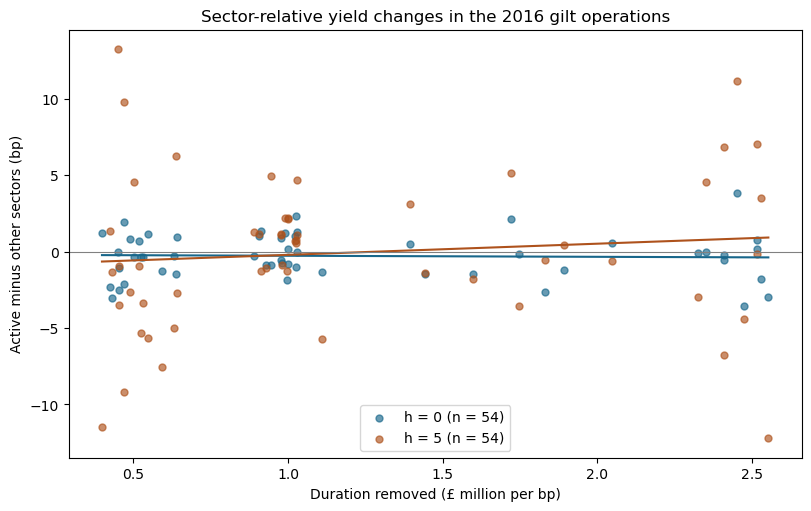

In [18]:
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
for h, colour in [(0, "#17668a"), (5, "#ae521c")]:
    points = op_h.loc[op_h["h"].eq(h), ["duration_removed", "SR"]].dropna()
    d, y = points["duration_removed"], points["SR"]
    ax.scatter(d, y, s=25, alpha=.65, color=colour, label=f"h = {h} (n = {len(d)})")
    if d.nunique() >= 2:
        limits = np.array([d.min(), d.max()])
        ax.plot(limits, np.polyval(np.polyfit(d, y, 1), limits), color=colour)
ax.axhline(0, color="0.5", lw=.8)
ax.set(xlabel="Duration removed (£ million per bp)", ylabel="Active minus other sectors (bp)",
       title="Sector-relative yield changes in the 2016 gilt operations")
ax.legend()
fig.savefig(c_out / "sector_yields_vs_duration.png", dpi=300)
plt.show()

### Step 11 sensitivity · Overlapping returns and the source of duration variation

Nearby operations share trading days in their five- and ten-day yield changes. Keep the original sector and month controls and report HC1 beside Newey–West standard errors with ten business-day lags and Bartlett weights. The regression has one row per operation. Non-operation dates carry zero regression score when measuring the gap between two operations. Both intervals use the same residual degrees of freedom.

At day ten, the duration slope is $-0.654$ bp per standard deviation. Its standard error rises from 3.558 to 5.067 bp. The second table attributes the squared deviations of duration from its sector-and-month prediction to each sector. The long sector supplies 71.16% of that remaining variation across the 54 operations.

In [19]:
# Step 11 sensitivity: operation-day scores on the business-day calendar.
focal = sector_results.loc[sector_results["term"].eq("duration_removed_z")].set_index("h")
sector_order = ["3–7", "7–15", "15+"]
hac_rows, share_rows = [], []
assert calendar.is_unique and calendar.is_monotonic_increasing

for h, ref in focal.iterrows():
    data = op_h.loc[op_h["h"].eq(h)].dropna(
        subset=["operation_date", "active_sector", "duration_removed", "SR"])
    dates = pd.DatetimeIndex(data["operation_date"])
    positions = calendar.get_indexer(dates)
    n, df = len(data), int(ref["residual_df"])
    assert n == ref["operations"] and dates.is_unique and (positions >= 0).all()

    shares = pd.Series(np.nan, index=sector_order)
    hac_se = np.nan
    if ref["estimable"]:
        d = data["duration_removed"]
        z = ((d - d.mean()) / d.std(ddof=1)).to_numpy()
        controls = np.column_stack([np.ones(n), *(data["active_sector"].eq(s) for s in sector_order[1:]),
                                    *(dates.month == m for m in range(9, 13))])
        zy = np.column_stack([z, data["SR"]])
        x, y = (zy - controls @ np.linalg.lstsq(controls, zy, rcond=None)[0]).T
        ss = x @ x
        assert ss > 0 and np.isclose(ss / (z @ z), ref["duration_variance_share_after_controls"])
        gamma = (x @ y) / ss
        np.testing.assert_allclose(gamma, ref["estimate_bp"], rtol=1e-7, atol=1e-10)
        shares = (data.assign(residual_sq=x**2).groupby("active_sector", observed=True)
                      ["residual_sq"].sum().reindex(sector_order, fill_value=0) / ss)
        assert np.isclose(shares.sum(), 1)
        if df > 0:
            score = np.zeros(len(calendar))
            score[positions] = x * (y - gamma * x) / ss
            hc1 = np.sqrt((n / df) * (score @ score))
            np.testing.assert_allclose(hc1, ref["HC1_se_bp"], rtol=1e-7, atol=1e-10)
            # Eleven-day moving sums give Bartlett weights 1 - lag/11 through lag 10.
            moving_sum = np.convolve(score, np.ones(11), mode="full")
            hac_se = np.sqrt((n / df) * (moving_sum @ moving_sum) / 11)

    margin = student_t.ppf(.975, df) * hac_se if df > 0 else np.nan
    hac_rows.append(dict(h=h, operations=n, residual_df=df, estimable=ref["estimable"],
                         gamma_bp=ref["estimate_bp"], HC1_se_bp=ref["HC1_se_bp"],
                         HC1_lower95_bp=ref["lower95_bp"], HC1_upper95_bp=ref["upper95_bp"],
                         HAC10_se_bp=hac_se, HAC10_lower95_bp=ref["estimate_bp"]-margin,
                         HAC10_upper95_bp=ref["estimate_bp"]+margin))
    for sector in sector_order:
        share_rows.append(dict(h=h, active_sector=sector, operations=int(data["active_sector"].eq(sector).sum()),
                               share_of_residual_duration_variation=shares[sector]))

sector_hac = pd.DataFrame(hac_rows)
duration_variation_by_sector = pd.DataFrame(share_rows)
sector_hac.to_csv(c_out / "sector_hac.csv", index=False)
duration_variation_by_sector.to_csv(c_out / "duration_variation_by_sector.csv", index=False)
show_table(sector_hac.round(4),
           'Duration regressions, 2016. Sector-spread coefficient per SD of duration removed, with HC1 and calendar-time HAC uncertainty (bp). Counts are operations.')
show_table(duration_variation_by_sector.round(4),
           '2016 duration regressions. Each sector’s fraction of the duration variation left after sector and month controls, with operation counts.')


,h,operations,residual_df,estimable,gamma_bp,HC1_se_bp,HC1_lower95_bp,HC1_upper95_bp,HAC10_se_bp,HAC10_lower95_bp,HAC10_upper95_bp
0,0,54,46,True,-0.7541,0.7813,-2.3267,0.8185,0.6074,-1.9766,0.4685
1,5,54,46,True,-1.1958,2.9867,-7.2077,4.8161,3.7642,-8.7727,6.3811
2,10,54,46,True,-0.6535,3.5583,-7.8159,6.5089,5.0668,-10.8524,9.5453


,h,active_sector,operations,share_of_residual_duration_variation
0,0,3–7,18,0.1570
1,0,7–15,18,0.1314
2,0,15+,18,0.7116
3,5,3–7,18,0.1570
4,5,7–15,18,0.1314
5,5,15+,18,0.7116
6,10,3–7,18,0.1570
7,10,7–15,18,0.1314
8,10,15+,18,0.7116


## Step 12. Describe the regression sample and account for exclusions

Report counts, means, sample standard deviations, quartiles and extremes for the eight variables in their original units. The day-zero sample contains 345 purchases. The median nominal allocation was £75m, and the median purchase was 0.283% of its gilt’s outstanding stock.

In [20]:
measures = {
    "total_allocation_nominal_mn": "Nominal allocation (£m)",
    "total_allocation_proceeds_mn": "Allocation proceeds (£m)",
    "amount_outstanding_mn": "Amount outstanding (£m nominal)",
    "relative_purchase": "Relative purchase (fraction)",
    "mod_duration_prev": "Prior modified duration (years)",
    "duration_value": "Duration value purchased (£m/bp)",
    "issue_illiquidity": "Issue-size illiquidity (negative log of £m outstanding)",
    "volatility": "Market volatility (bp)"
}
description = regression[list(measures)].rename(columns=measures).describe().T.rename(
    columns={"count": "n", "std": "sd", "50%": "median"}
)
description["n"] = description["n"].astype(int)
description.to_csv(c_out / "summary_statistics.csv", index_label="variable")
show_table(description.round(4),
           '2016 purchases with a measurable day-zero abnormal yield. Variable units are in the row labels; n counts available purchases.')


,n,mean,sd,min,25%,median,75%,max
Nominal allocation (£m),345,136.4707,148.2278,3.9000,30.0000,75.0000,193.0000,836.4000
Allocation proceeds (£m),345,170.8586,175.1691,4.1818,41.6933,100.3253,246.5751,821.0087
Amount outstanding (£m nominal),345,26279.7494,6648.0642,4874.9990,23208.7940,27343.6800,29761.9120,37947.5880
Relative purchase (fraction),345,0.0058,0.0086,0.0001,0.0013,0.0028,0.0076,0.0929
Prior modified duration (years),345,12.9151,8.1793,2.8700,5.6500,11.0600,19.5300,32.3100
Duration value purchased (£m/bp),345,0.1817,0.2041,0.0016,0.0412,0.1143,0.2566,1.5672
Issue-size illiquidity (negative log of £m outstanding),345,-10.1288,0.3510,-10.5440,-10.3010,-10.2162,-10.0523,-8.4919
Market volatility (bp),345,4.2357,0.5372,2.9021,3.9335,4.3725,4.5710,5.1848


**Sample construction.** Start with 361 purchases. Requiring a comparison gilt leaves 345. All 345 have a measurable day-zero abnormal yield. Removing 21 windows contaminated by day four leaves 324. The exclusions file records each removed purchase once, with its first reason for exclusion.

In [21]:
audit = purchases.set_index(keys)[["bond"]].copy()
for source in [
    matches.set_index(keys)["match_type"],
    panel.loc[panel["h"].eq(0)].set_index(keys)["AY"],
    panel.loc[panel["h"].eq(4)].set_index(keys)["contaminated"]
]:
    audit = audit.join(source, validate="1:1")
assert audit["match_type"].isin(["bracketed", "nearest-neighbour", "unmatched"]).all()
assert audit["contaminated"].isin([0, 1]).all()

matched = audit["match_type"].ne("unmatched")
valid_day0 = matched & audit["AY"].notna()
clean_day4 = valid_day0 & audit["contaminated"].eq(0)
assert not regression.duplicated(keys).any()
assert set(audit.index[valid_day0]) == set(regression.set_index(keys).index)

remaining = pd.Series(
    [len(audit), matched.sum(), valid_day0.sum(), clean_day4.sum()],
    index=["All purchases", "Comparison gilt found", "AY(0) available", "Uncontaminated at day 4"],
    name="remaining", dtype=int
)
construction = remaining.to_frame()
construction["removed_at_step"] = -remaining.diff().fillna(0).astype(int)

audit["Exclusion reason"] = np.select(
    [~matched, ~valid_day0, ~clean_day4],
    ["no comparison gilt", "missing abnormal yield", "contaminated event window"], default=""
)
exclusions = audit.loc[~clean_day4, ["bond", "Exclusion reason"]].reset_index()
reason_counts = exclusions["Exclusion reason"].value_counts().reindex(
    ["no comparison gilt", "missing abnormal yield", "contaminated event window"], fill_value=0
)
np.testing.assert_array_equal(reason_counts, construction["removed_at_step"].iloc[1:])
assert not exclusions.duplicated(keys).any()
assert len(exclusions) + int(clean_day4.sum()) == len(purchases)
construction.to_csv(c_out / "sample_construction.csv", index_label="stage")
exclusions.to_csv(c_out / "excluded_purchases.csv", index=False)
show_table(construction,
           'Sample construction for 2016 gilt purchases. Counts are gilt–operation pairs surviving and removed at each stage.')

print(f"Clean at day 4: {int(clean_day4.sum())} purchases. "
      f"With a day-4 abnormal yield: {len(day4)}. "
      f"Used by the day-4 regression: {int(results.loc[results['model'].eq('Four days later'), 'n'].iloc[0])}.")

,remaining,removed_at_step
All purchases,361,0
Comparison gilt found,345,16
AY(0) available,345,0
Uncontaminated at day 4,324,21


Clean at day 4: 324 purchases. With a day-4 abnormal yield: 324. Used by the day-4 regression: 324.


## Additional check. Yield changes among unpurchased gilts

Recalculate the day-zero sector spread using only unpurchased gilts in the active sector, keeping Step 11’s other-sector benchmark. On the 53 operations with unpurchased peers, their mean spread was $-0.354$ bp, compared with $-0.279$ bp for the whole active sector on those same dates. This descriptive comparison includes maturity-specific news as well as any purchase effects. On 30 August every long-sector gilt was bought, so the unpurchased spread is missing.

In [22]:
day0 = sector_panel.loc[sector_panel["h"].eq(0)].copy()
day0 = day0.loc[day0["sector"].eq(day0["operation_date"].map(operation["active_sector"]))]
groups = day0.groupby(["operation_date", "purchased"])["active_change"]
counts = groups.count().unstack(fill_value=0).reindex(columns=[0, 1], fill_value=0)
means = groups.mean().unstack().reindex(columns=[0, 1])

sector_check = op_h.loc[op_h["h"].eq(0)].set_index("operation_date")[
    ["active_sector", "active_gilts", "other_gilts", "other_change_bp", "SR"]
].copy()
sector_check[["n_unpurchased", "n_purchased"]] = counts
sector_check["purchased_share"] = counts[1].div(sector_check["active_gilts"].replace(0, np.nan))
sector_check["purchased_relative_bp"] = means[1] - sector_check["other_change_bp"]
sector_check["unpurchased_relative_bp"] = means[0] - sector_check["other_change_bp"]

assert len(sector_check) == len(ops) and sector_check.index.is_unique
assert counts.sum(axis=1).eq(sector_check["active_gilts"]).all()
weights = sector_check["purchased_share"]
bought_term = (weights * sector_check["purchased_relative_bp"]).mask(counts[1].eq(0), 0)
unbought_term = ((1 - weights) * sector_check["unpurchased_relative_bp"]).mask(counts[0].eq(0), 0)
reconstructed = (bought_term + unbought_term).where(sector_check["active_gilts"].gt(0))
np.testing.assert_allclose(reconstructed, sector_check["SR"], atol=1e-10, rtol=0, equal_nan=True)
sector_check.to_csv(c_out / "sector_unpurchased_check.csv")
show_table(sector_check.round(3),
           'Operation-day yield changes in the active sector relative to other eligible gilts (bp), August–December 2016. Each row gives the contributing gilt counts.')


,active_sector,active_gilts,other_gilts,other_change_bp,SR,n_unpurchased,n_purchased,purchased_share,purchased_relative_bp,unpurchased_relative_bp
operation_date,,,,,,,,,,
2016-08-08,3–7,10,24,-3.905,-0.022,6,4,0.400,0.084,-0.092
2016-08-09,15+,16,18,-3.327,-2.958,2,14,0.875,-2.938,-3.101
2016-08-10,7–15,8,26,-5.216,2.302,2,6,0.750,2.409,1.979
2016-08-15,3–7,10,24,3.734,-2.530,4,6,0.600,-2.565,-2.476
2016-08-16,15+,16,18,4.683,-0.077,6,10,0.625,-0.034,-0.150
2016-08-17,7–15,8,26,-0.433,-0.823,2,6,0.750,-0.710,-1.164
2016-08-22,3–7,10,24,-4.293,1.969,5,5,0.500,1.895,2.042
2016-08-23,15+,16,18,-1.425,-3.537,2,14,0.875,-3.514,-3.703
2016-08-24,7–15,8,26,0.724,1.032,2,6,0.750,1.080,0.888


**Known-effect test on synthetic quotes.** The final test operation bought three of the five gilts in its sector. The test lowers yields by 3 bp on that date only and repeats the calculations. Each entry below is the change from the same unperturbed run, in basis points.

| Gilts receiving the temporary fall | Matched operation-day effect | Matched day-four reversal | Full sector spread | Unpurchased spread |
|---|---:|---:|---:|---:|
| Three purchased gilts | −3.0 | +3.0 | −1.8 | 0.0 |
| All five active-sector gilts | 0.0 | 0.0 | −3.0 | −3.0 |

The first row gives $-3\times 3/5=-1.8$ bp in the full sector measure even though neither unpurchased gilt was shocked. In the second row, the comparison gilts absorb the same yield shift as the purchased gilts, so the matched effect cancels. On the original files, the new `unpurchased_relative_bp` column gives the corresponding observed spread for each operation.

## Sensitivity checks on the repository data

These checks vary one choice at a time. Part A removes comparison windows sharing an event day. Part B uses only purchases with an unpurchased gilt on each side of their maturity. Part C refits each sector regression 54 times, omitting one operation at a time and restandardising duration in the remaining sample.

In [23]:
next_day = calendar[calendar.get_loc(event) + 1]
two_day = compare_window(gaps["two_day_bp"].drop(index=[base, next_day]))
print(f"Two-day gap against non-overlapping comparison windows: z = {two_day['z']:.3f}, "
      f"{int(two_day['at_least_as_negative'])} of {int(two_day['other_windows'])} as negative.")

bracketed = matches.set_index(keys)["match_type"].eq("bracketed").reindex(effects.index)
for label, col in [("Operation day", "operation_day_bp"), ("Day-four reversal", "day_4_reversal_bp")]:
    result = operation_summary(effects.loc[bracketed, col])
    print(f"{label}, bracketed matches: {result['mean_bp']:+.4f} bp "
          f"(95% CI [{result['lower_95_bp']:+.4f}, {result['upper_95_bp']:+.4f}], "
          f"{result['operations']} operations).")

for h, group in op_h.groupby("h"):
    slopes = []
    for row in group.index:
        fit = fit_sector(h, group.drop(index=row)).set_index("term")
        slopes.append(fit.at["duration_removed_z", "estimate_bp"])
    print(f"Day {h}, omitting one operation: duration slope {min(slopes):+.3f} to "
          f"{max(slopes):+.3f} bp. Negative in {sum(x < 0 for x in slopes)}/{len(slopes)} fits.")

Two-day gap against non-overlapping comparison windows: z = -2.625, 1 of 113 as negative.
Operation day, bracketed matches: +0.0086 bp (95% CI [-0.0541, +0.0713], 50 operations).
Day-four reversal, bracketed matches: -0.0424 bp (95% CI [-0.2233, +0.1386], 49 operations).
Day 0, omitting one operation: duration slope -1.078 to -0.434 bp. Negative in 54/54 fits.
Day 5, omitting one operation: duration slope -2.299 to +0.615 bp. Negative in 53/54 fits.
Day 10, omitting one operation: duration slope -2.285 to +1.801 bp. Negative in 52/54 fits.
